# Image Finder · semantic image retrieval
Find related images with **CLIP ViT-B/32**, L2 normalization, and cosine similarity.

[GitHub](https://github.com/AbdulrahmanAKh/Image_Finder_Project) · [Live demo](https://AbdulrahmanAKh.github.io/Image_Finder_Project/) · [Open in Colab](https://colab.research.google.com/github/AbdulrahmanAKh/Image_Finder_Project/blob/main/Image_Finder_CLIP.ipynb)

## What changed from the original notebook?
The original EfficientNetV2 notebook omitted ImageNet normalization, flattened spatial feature maps instead of pooling, fitted PCA without evaluating its effect, sampled without a seed, and excluded the query by assuming it was the highest-scoring result. It also displayed cosine similarity as a percentage that could be mistaken for confidence.

Here we use CLIP's pretrained image projection and official preprocessing, giving one 512-dimensional vector per image. We remove PCA, use a deterministic balanced gallery, explicitly exclude gallery queries, support uploaded images, and evaluate separate query images. CLIP is a semantic retrieval candidate; superiority over a correctly preprocessed EfficientNetV2 is **not established** by this notebook. The measured baseline below is a simple color descriptor.

## Dataset and scope
[Tiny ImageNet](https://huggingface.co/datasets/zh-plus/tiny-imagenet) covers 200 categories, including animals, objects, food, and scenes. We use **2,000 gallery images (10 per category)** and **200 disjoint queries (one per category)** from its validation split. This is a small educational subset, not a search of the internet or the complete dataset. Original images are only 64 × 64 pixels, limiting fine-detail matching. Class relevance is a proxy for semantic similarity; these are not instance-retrieval ground-truth labels.

Images remain subject to the dataset's [ImageNet terms](https://huggingface.co/datasets/zh-plus/tiny-imagenet/blob/main/README.md) and original owners' rights. Intended for noncommercial education/research; the code license does not license the images. CLIP may contain training-data bias; pretraining overlap cannot be ruled out.

## 1. Install
Run all cells in order. CPU works; building the gallery takes several minutes. The quantized ONNX vision encoder (~89 MB) is used by both Python and the website, avoiding a second model implementation. No API key is needed.

In [1]:
%pip -q install onnxruntime==1.31.1 transformers==5.6.2 pyarrow==26.0.1 pillow requests matplotlib numpy

Dependencies installed in the local verification environment. Run this cell when opening in Colab.


## 2. Download the dataset and model
Files are cached locally. Only the vision encoder is downloaded, since image-to-image search does not need CLIP’s text encoder.

In [2]:
from pathlib import Path
from io import BytesIO
import json, time, hashlib, ast
import numpy as np
import requests
import pyarrow.parquet as pq
from PIL import Image, ImageOps
import onnxruntime as ort
from transformers import CLIPImageProcessor
import matplotlib.pyplot as plt

SEED = 42
CACHE = Path(".cache")
CACHE.mkdir(exist_ok=True)
DATASET_REV = "5a77092c28e51558c5586e9c5eb71a7e17a5e43f"
DATASET_URL = f"https://huggingface.co/datasets/zh-plus/tiny-imagenet/resolve/{DATASET_REV}"
MODEL_REV = "6b7c523703ae26e39be4b03774966f8571c7f523"
MODEL_URL = f"https://huggingface.co/Xenova/clip-vit-base-patch32/resolve/{MODEL_REV}"

def download(url, path):
    path = Path(path)
    if not path.exists():
        response = requests.get(url, timeout=180)
        response.raise_for_status()
        temp = path.with_suffix(path.suffix + ".tmp")
        temp.write_bytes(response.content)
        temp.replace(path)
    return path

data_file = download(DATASET_URL + "/data/valid-00000-of-00001-70d52db3c749a935.parquet", CACHE / "tiny-valid.parquet")
info_file = download(DATASET_URL + "/dataset_infos.json", CACHE / "dataset_infos.json")
model_file = download(MODEL_URL + "/onnx/vision_model_quantized.onnx", CACHE / "vision_model_quantized.onnx")
download(MODEL_URL + "/preprocessor_config.json", CACHE / "preprocessor_config.json")
label_file = download(DATASET_URL + "/classes.py", CACHE / "classes.py")
table = pq.read_table(data_file).to_pydict()
wnids = next(iter(json.loads(info_file.read_text()).values()))["features"]["label"]["names"]
label_names = {key: value.split(",")[0] for key, value in ast.literal_eval(ast.parse(label_file.read_text(encoding="utf-8")).body[0].value).items()}
labels = np.array(table["label"])
print(f"Loaded {len(labels):,} validation images across {len(np.unique(labels))} categories.")

[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
Loaded 10,000 validation images across 200 categories.


## 3. Make a balanced gallery and separate queries
A seeded sample reserves ten gallery images and one query per category. Identical RGB content is deduplicated before selecting, so a duplicated file cannot inflate evaluation.

In [3]:
def get_image(row):
    return Image.open(BytesIO(table["image"][int(row)]["bytes"])).convert("RGB")

rng = np.random.default_rng(SEED)
gallery_ids, query_ids, seen = [], [], set()
for label in sorted(np.unique(labels)):
    chosen = []
    for row in rng.permutation(np.flatnonzero(labels == label)):
        digest = hashlib.sha256(get_image(row).tobytes()).hexdigest()
        if digest not in seen:
            seen.add(digest)
            chosen.append(int(row))
        if len(chosen) == 11:
            break
    assert len(chosen) == 11, "Not enough distinct images in a category"
    gallery_ids.extend(chosen[:10])
    query_ids.append(chosen[10])
gallery_labels = labels[gallery_ids]
query_labels = labels[query_ids]
assert not set(gallery_ids) & set(query_ids)
print(f"Gallery: {len(gallery_ids):,} · Held-out queries: {len(query_ids)}")

Gallery: 2,000 · Held-out queries: 200


## 4. Extract normalized CLIP vectors
The official processor resizes, center-crops, converts to RGB, and applies CLIP’s mean/std normalization. L2-normalized vectors make the dot product equal cosine similarity. Small batches keep CPU memory use manageable.

In [4]:
processor = CLIPImageProcessor.from_pretrained(str(CACHE))
options = ort.SessionOptions()
options.intra_op_num_threads = 4
session = ort.InferenceSession(str(model_file), sess_options=options, providers=["CPUExecutionProvider"])

def embed(images):
    pixels = processor(images=images, return_tensors="np")["pixel_values"]
    vectors = session.run(["image_embeds"], {"pixel_values": pixels})[0]
    return vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)

def encode_rows(rows, batch_size=8):
    vectors = []
    for start in range(0, len(rows), batch_size):
        vectors.append(embed([get_image(row) for row in rows[start:start + batch_size]]))
        if start % 200 == 0:
            print(f"Encoded {min(start + batch_size, len(rows))}/{len(rows)}", flush=True)
    return np.concatenate(vectors).astype("float32")

cache_key = hashlib.sha256((DATASET_REV + MODEL_REV + json.dumps(gallery_ids + query_ids)).encode()).hexdigest()[:16]
vector_file = CACHE / f"clip-{cache_key}.npz"
started = time.perf_counter()
if vector_file.exists():
    cached = np.load(vector_file)
    gallery_vectors, query_vectors = cached["gallery_vectors"], cached["query_vectors"]
    print("Loaded cached embeddings for the same model, dataset, and selected rows.")
else:
    gallery_vectors = encode_rows(gallery_ids)
    query_vectors = encode_rows(query_ids)
    np.savez_compressed(vector_file, gallery_vectors=gallery_vectors, query_vectors=query_vectors)
print(f"Shape: {gallery_vectors.shape}; encoding/loading took {time.perf_counter() - started:.1f} seconds")

Loaded cached embeddings for the same model, dataset, and selected rows.
Shape: (2000, 512); encoding/loading took 0.1 seconds


## 5. Retrieve and display
Scores range from −1 to 1. Higher means more similar in this model’s embedding space; it is not a confidence percentage. Sample queries below come from the held-out set. Gallery queries can pass `exclude_index` explicitly.

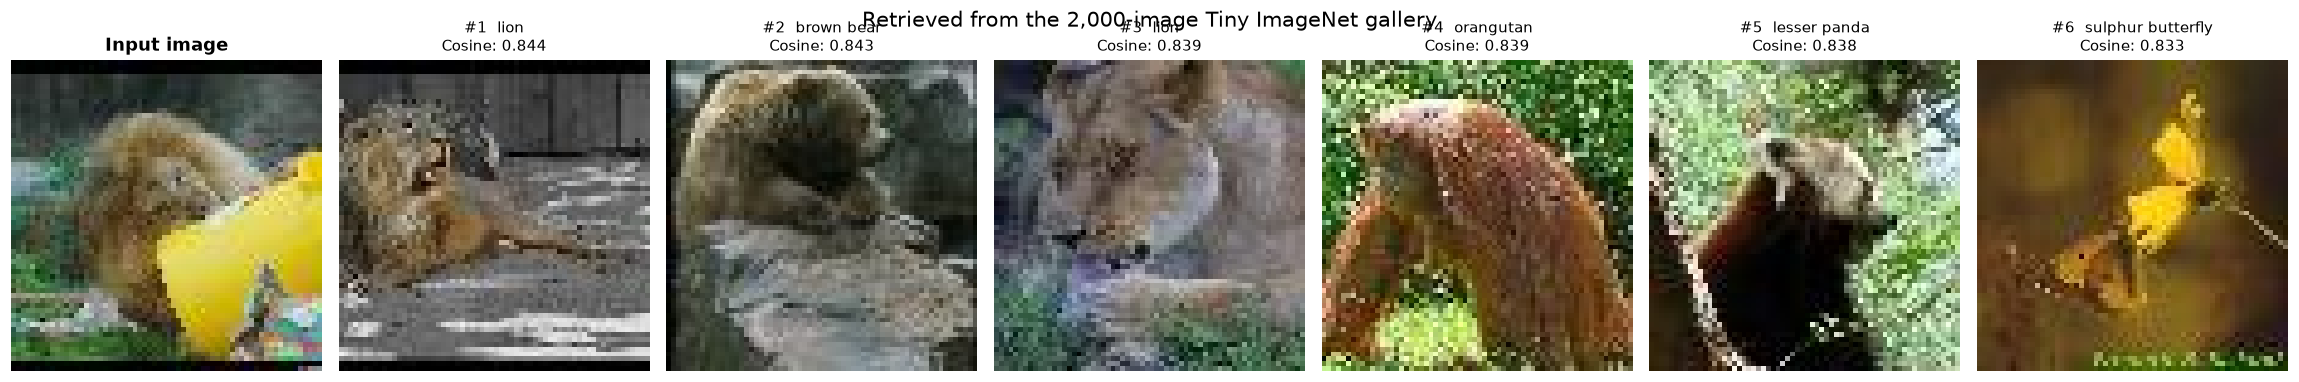

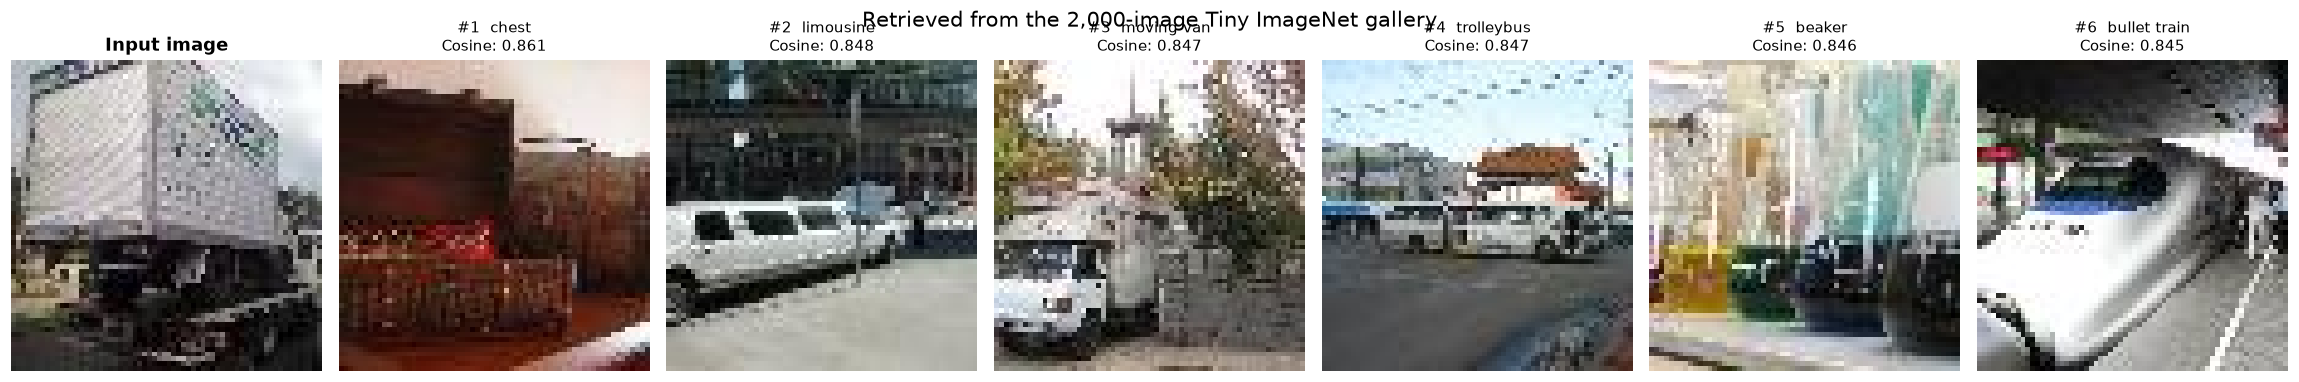

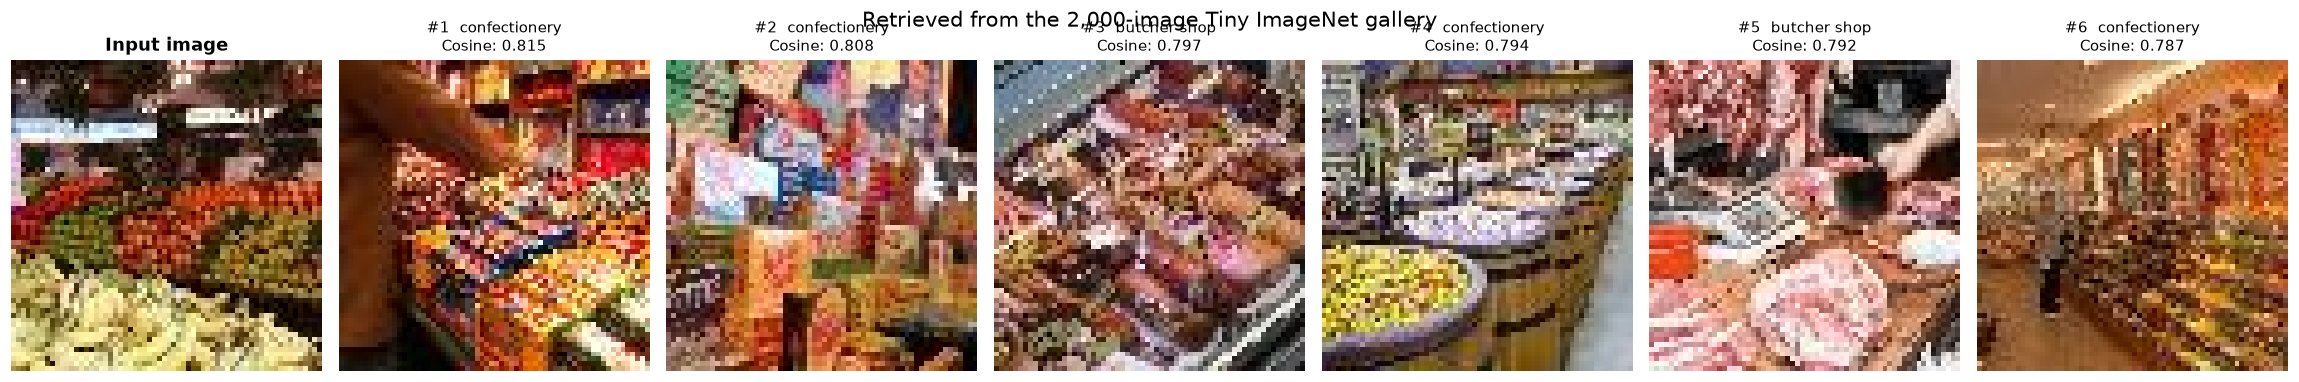

In [5]:
def search(vector, k=6, exclude_index=None):
    scores = gallery_vectors @ np.asarray(vector).reshape(-1)
    if exclude_index is not None:
        scores[exclude_index] = -np.inf
    order = np.argsort(-scores, kind="stable")[:k]
    return order, scores[order]

def show_results(image, vector=None, k=6, exclude_index=None):
    vector = embed([image])[0] if vector is None else vector
    order, scores = search(vector, k, exclude_index)
    fig, axes = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3.5))
    axes[0].imshow(image)
    axes[0].set_title("Input image", fontweight="bold")
    for rank, (index, score) in enumerate(zip(order, scores), 1):
        axes[rank].imshow(get_image(gallery_ids[index]))
        name = label_names.get(wnids[gallery_labels[index]], wnids[gallery_labels[index]])
        axes[rank].set_title(f"#{rank}  {name}\nCosine: {score:.3f}", fontsize=10)
    for axis in axes:
        axis.axis("off")
    fig.suptitle("Retrieved from the 2,000-image Tiny ImageNet gallery", fontsize=14)
    plt.tight_layout()
    plt.show()

for query_index in [31, 113, 178]:
    show_results(get_image(query_ids[query_index]), query_vectors[query_index])

## 6. Evaluate retrieval
Precision@5 measures the fraction of five results sharing the query class. Hit@5 measures whether at least one shares it. The simple baseline uses a normalized 8 × 8 RGB descriptor; it is **not EfficientNet**. Both methods use the exact same gallery and held-out queries. The validation split is partitioned for this experiment; it is not a new independent benchmark. No model is fine-tuned here.

CLIP ViT-B/32 (q8)       Precision@5: 0.250 | Hit@5: 0.580
8x8 RGB baseline         Precision@5: 0.012 | Hit@5: 0.060


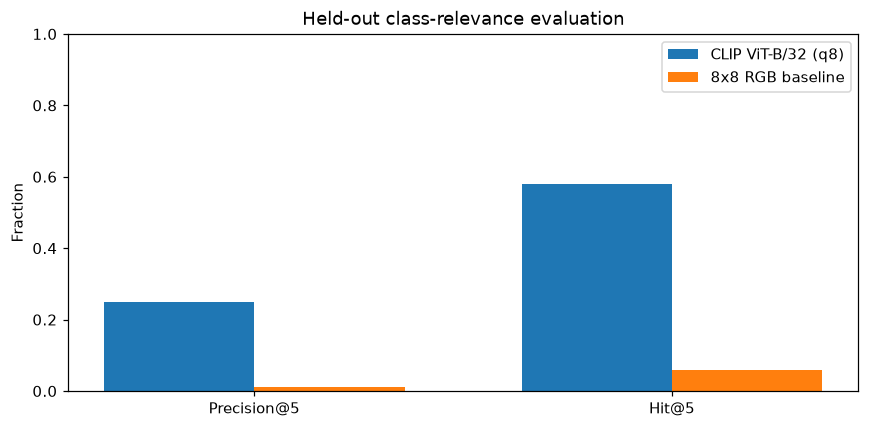

In [6]:
def metrics(gallery, queries):
    scores = queries @ gallery.T
    order = np.argsort(-scores, axis=1, kind="stable")[:, :5]
    relevant = gallery_labels[order] == query_labels[:, None]
    return {"Precision@5": float(relevant.mean()), "Hit@5": float(relevant.any(axis=1).mean())}

def color_vectors(rows):
    vectors = np.array([np.asarray(get_image(row).resize((8, 8))).flatten() for row in rows], dtype="float32")
    return vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)

evaluation = {"CLIP ViT-B/32 (q8)": metrics(gallery_vectors, query_vectors),
              "8x8 RGB baseline": metrics(color_vectors(gallery_ids), color_vectors(query_ids))}
for name, values in evaluation.items():
    print(f"{name:24s} " + " | ".join(f"{key}: {value:.3f}" for key, value in values.items()))
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(2)
for offset, (name, values) in zip([-0.18, 0.18], evaluation.items()):
    ax.bar(x + offset, list(values.values()), width=0.36, label=name)
ax.set(xticks=x, xticklabels=["Precision@5", "Hit@5"], ylim=(0, 1), ylabel="Fraction", title="Held-out class-relevance evaluation")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Try your own image
In Colab, run this cell to select a local image. Locally, replace `UPLOAD_PATH` with a file path. Photos outside the gallery’s categories still receive nearest neighbors; this does not establish relevance. The model sees a center crop, so keep the main subject near the center.

In [7]:
UPLOAD_PATH = None  # Example: "my_photo.jpg"
try:
    from google.colab import files
except ImportError:
    files = None

if files is not None:
    uploaded = files.upload()
    if uploaded:
        UPLOAD_PATH = next(iter(uploaded))
if UPLOAD_PATH:
    image = ImageOps.exif_transpose(Image.open(UPLOAD_PATH)).convert("RGB")
    show_results(image)
else:
    print("Set UPLOAD_PATH or run this cell in Colab to upload a photo.")

Set UPLOAD_PATH or run this cell in Colab to upload a photo.


## 8. Export the website gallery
The browser downloads this small index and loads the same q8 encoder only for uploaded images. Ready-made held-out samples use cached embeddings for an instant demonstration. Exports include model/dataset identifiers and checksums for reproducibility. Never change the encoder without rebuilding the index.

In [8]:
EXPORT = Path("docs/data")
EXPORT.mkdir(parents=True, exist_ok=True)
(EXPORT / "images").mkdir(exist_ok=True)
items = []
for index, row in enumerate(gallery_ids):
    filename = f"images/{index:04d}.png"
    get_image(row).save(EXPORT / filename)
    items.append({"id": int(row), "label": label_names.get(wnids[labels[row]], wnids[labels[row]]), "category": int(labels[row]), "image": filename})
samples = []
for index in [0, 31, 57, 113, 178, 188]:
    row = query_ids[index]
    filename = f"images/sample-{index}.png"
    get_image(row).save(EXPORT / filename)
    samples.append({"id": int(row), "label": label_names.get(wnids[labels[row]], wnids[labels[row]]), "image": filename, "vector": query_vectors[index].tolist()})
gallery_vectors.astype("<f4").tofile(EXPORT / "embeddings.f32")
manifest = {"dataset": "Tiny ImageNet", "dataset_url": "https://huggingface.co/datasets/zh-plus/tiny-imagenet",
            "dataset_revision": DATASET_REV, "split": "valid", "seed": SEED,
            "model": "Xenova/clip-vit-base-patch32", "model_revision": MODEL_REV, "dtype": "q8", "dimensions": 512,
            "model_sha256": hashlib.sha256(model_file.read_bytes()).hexdigest(),
            "dataset_sha256": hashlib.sha256(data_file.read_bytes()).hexdigest(),
            "count": len(items), "categories": 200, "items": items, "samples": samples,
            "evaluation": evaluation, "query_count": len(query_ids)}
(EXPORT / "manifest.json").write_text(json.dumps(manifest), encoding="utf-8")
np.savez_compressed("retrieval_index.npz", gallery_vectors=gallery_vectors, query_vectors=query_vectors,
                    gallery_ids=gallery_ids, query_ids=query_ids)
print(f"Exported {len(items):,} gallery images and {len(samples)} held-out samples to {EXPORT}")

Exported 2,000 gallery images and 6 held-out samples to docs\data


## Next steps
Use a larger, appropriately licensed high-resolution dataset for production. Compare CLIP with correctly normalized and globally pooled EfficientNetV2 on the same held-out protocol before choosing for a particular domain. For millions of images, replace the exact dot product with a vector index such as FAISS. No PCA is necessary for this 2,000 × 512 index (~4 MB).

## Author
- GitHub: [@AbdulrahmanAKh](https://github.com/AbdulrahmanAKh)
- LinkedIn: [Abdulrahman Alkhatib](https://www.linkedin.com/in/abdulrahman-alkhatib/)
- Email: [aboodkhatib90@gmail.com](mailto:aboodkhatib90@gmail.com)
- Portfolio: [abdulrahmanakh.github.io](https://abdulrahmanakh.github.io/)

---
<p align="center"><b>Developed &amp; Engineered by Abdulrahman Alkhatib</b><br><i>Computer Science Graduate | Software &amp; AI Engineer</i></p>